Setup

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data_loader import load_year
from src.preprocessing import (clean_salary, build_features, education_level)

os.makedirs("reports", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

Load 2025 and clean the salary

In [2]:
df = load_year(2025)
print("Rows in survey:", len(df))
print("Salary missing: %.1f%%" % (df["ConvertedCompYearly"].isnull().mean() * 100))

df_clean, lo, hi = clean_salary(df)
df_clean = df_clean[df_clean["LanguageHaveWorkedWith"].notna()]
print("Rows with usable salary + languages:", len(df_clean))
print(f"Kept salaries between {lo:,.0f} and {hi:,.0f}")

2025: already downloaded
Rows in survey: 49191
Salary missing: 51.3%
Rows with usable salary + languages: 21744
Kept salaries between 65 and 440,856


Look at the salary shape (visual)

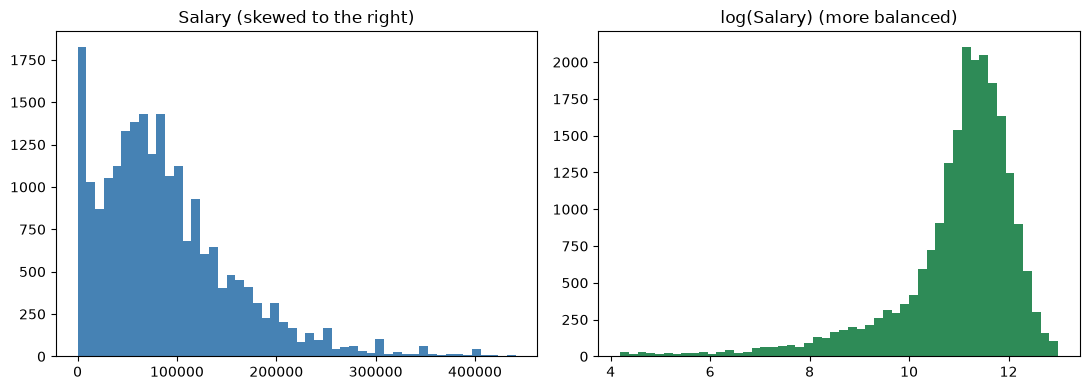

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(df_clean["ConvertedCompYearly"], bins=50, color="steelblue")
ax[0].set_title("Salary (skewed to the right)")
ax[1].hist(np.log1p(df_clean["ConvertedCompYearly"]), bins=50, color="seagreen")
ax[1].set_title("log(Salary) (more balanced)")
plt.tight_layout()
plt.savefig("reports/salary_distribution.png", dpi=150)
plt.show()

Build the features

In [4]:
X, tech_cols = build_features(df_clean)
print("Skill columns found:", tech_cols)
print("Feature table shape:", X.shape)

# Check that every education answer was understood
unmapped = df_clean.loc[df_clean["EdLevel"].notna() &
                        df_clean["EdLevel"].apply(education_level).isna(),
                        "EdLevel"].value_counts()
print("\nEducation answers NOT mapped (should be few):")
print(unmapped)
X.head()

Skill columns found: ['LanguageHaveWorkedWith', 'DatabaseHaveWorkedWith', 'PlatformHaveWorkedWith', 'WebframeHaveWorkedWith', 'DevEnvsHaveWorkedWith', 'SOTagsHaveWorkedWith', 'OfficeStackAsyncHaveWorkedWith', 'CommPlatformHaveWorkedWith', 'AIModelsHaveWorkedWith']
Feature table shape: (21744, 86)

Education answers NOT mapped (should be few):
EdLevel
Other (please specify):    190
Name: count, dtype: int64


,years_code,edu_level,num_skills,Language_JavaScript,Language_HTML/CSS,Language_SQL,Language_Python,Language_Bash/Shell (all shells),Language_TypeScript,Language_C#,...,country_Canada,country_France,country_Germany,country_India,country_Netherlands,country_Other,country_Poland,country_Ukraine,country_United Kingdom of Great Britain and Northern Ireland,country_United States of America
0,14.0,6.0,29,0,0,1,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
1,10.0,4.0,31,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
2,12.0,5.0,27,1,1,0,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
3,5.0,5.0,14,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,22.0,6.0,52,1,1,1,1,0,1,1,...,0,0,0,0,0,0,0,1,0,0


Targets and the train/test split

In [5]:
from sklearn.model_selection import train_test_split

salary = df_clean["ConvertedCompYearly"]
y_reg = np.log1p(salary)                       # for salary prediction (Step 5)
y_cls = (salary > salary.median()).astype(int) # 1 = above-median salary (Step 6)

X_train, X_test, ytr_reg, yte_reg, ytr_cls, yte_cls = train_test_split(
    X, y_reg, y_cls, test_size=0.2, random_state=42)

# Fill missing numbers using the TRAIN medians only (no leakage)
medians = X_train[["years_code", "edu_level"]].median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("High-salary share in train: %.2f" % ytr_cls.mean())

Train: (17395, 86)  Test: (4349, 86)
High-salary share in train: 0.50


Scaling


 RAW
      years_code  edu_level  num_skills
mean       17.93       4.97        32.5
std        10.96       1.25        16.5
min         1.00       1.00         1.0
max       100.00       7.00       249.0

 STANDARDISED
      years_code  edu_level  num_skills
mean       -0.00      -0.00        0.00
std         1.00       1.00        1.00
min        -1.54      -3.18       -1.91
max         7.49       1.63       13.12

 MIN-MAX
      years_code  edu_level  num_skills
mean        0.17       0.66        0.13
std         0.11       0.21        0.07
min         0.00       0.00        0.00
max         1.00       1.00        1.00


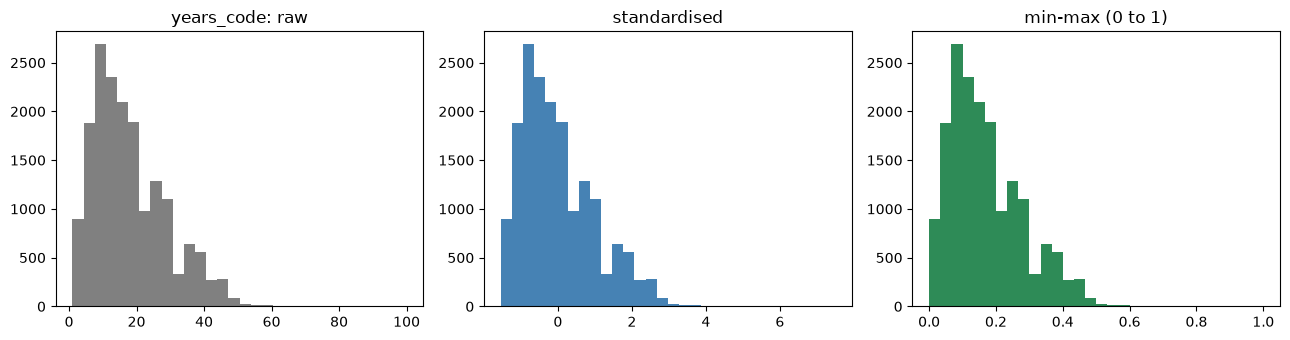

In [6]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

num_cols = ["years_code", "edu_level", "num_skills"]

std = StandardScaler().fit(X_train[num_cols])   # learn from TRAIN only
mm = MinMaxScaler().fit(X_train[num_cols])

raw = X_train[num_cols]
stdz = pd.DataFrame(std.transform(raw), columns=num_cols)
mmx = pd.DataFrame(mm.transform(raw), columns=num_cols)

for name, d in [("RAW", raw), ("STANDARDISED", stdz), ("MIN-MAX", mmx)]:
    print("\n", name)
    print(d.describe().loc[["mean", "std", "min", "max"]].round(2))

# Visual: same feature, three scales
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].hist(raw["years_code"], bins=30, color="gray");      ax[0].set_title("years_code: raw")
ax[1].hist(stdz["years_code"], bins=30, color="steelblue"); ax[1].set_title("standardised")
ax[2].hist(mmx["years_code"], bins=30, color="seagreen");   ax[2].set_title("min-max (0 to 1)")
plt.tight_layout()
plt.savefig("reports/scaling_comparison.png", dpi=150)
plt.show()

PCA

Original features: 86
Components needed to keep 90% of the information: 66


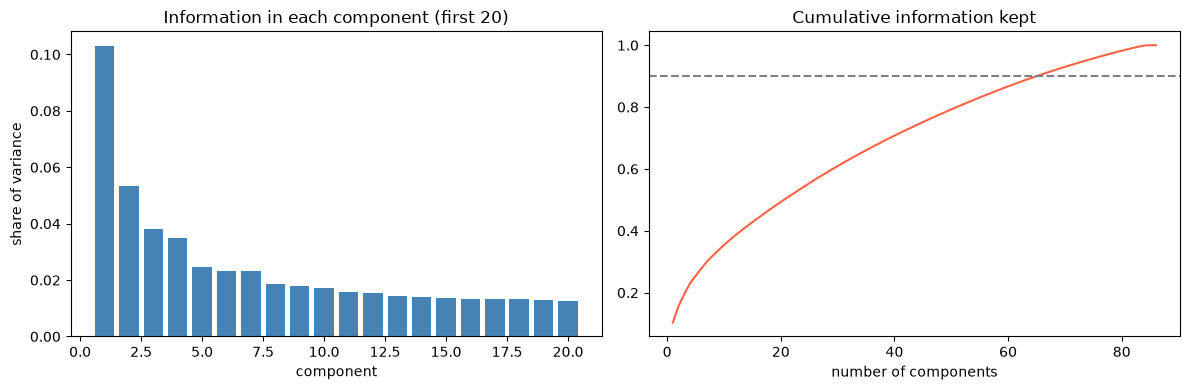

Variance kept by the 2 components: 15.6%


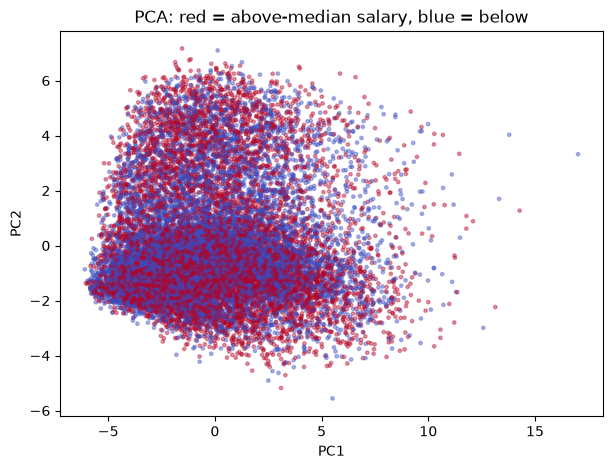

In [8]:
from sklearn.decomposition import PCA

# PCA needs ALL features on the same scale, so standardise every column
scaler_all = StandardScaler().fit(X_train)
Z_train = scaler_all.transform(X_train)

pca = PCA().fit(Z_train)
cum = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.argmax(cum >= 0.90)) + 1
print("Original features:", Z_train.shape[1])
print("Components needed to keep 90%% of the information: %d" % n90)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, 21), pca.explained_variance_ratio_[:20], color="steelblue")
ax[0].set_title("Information in each component (first 20)")
ax[0].set_xlabel("component"); ax[0].set_ylabel("share of variance")
ax[1].plot(range(1, len(cum) + 1), cum, color="tomato")
ax[1].axhline(0.90, linestyle="--", color="gray")
ax[1].set_title("Cumulative information kept")
ax[1].set_xlabel("number of components")
plt.tight_layout()
plt.savefig("reports/pca_variance.png", dpi=150)
plt.show()

# 2D picture of all respondents
pca2 = PCA(n_components=2).fit(Z_train)
P = pca2.transform(Z_train)
print("Variance kept by the 2 components: %.1f%%" % (pca2.explained_variance_ratio_.sum() * 100))

plt.figure(figsize=(7, 5))
plt.scatter(P[:, 0], P[:, 1], c=ytr_cls, cmap="coolwarm", s=6, alpha=0.4)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("PCA: red = above-median salary, blue = below")
plt.savefig("reports/pca_2d.png", dpi=150)
plt.show()

### PCA observation
The first two principal components keep only about 15.6% of the variance,
and above-median and below-median salaries overlap heavily in the 2D plot.
So a 2D projection is not enough to separate salary groups. This motivates
the supervised models in later steps. PCA here is used to understand the
data structure, not to claim predictive power.

Correlation

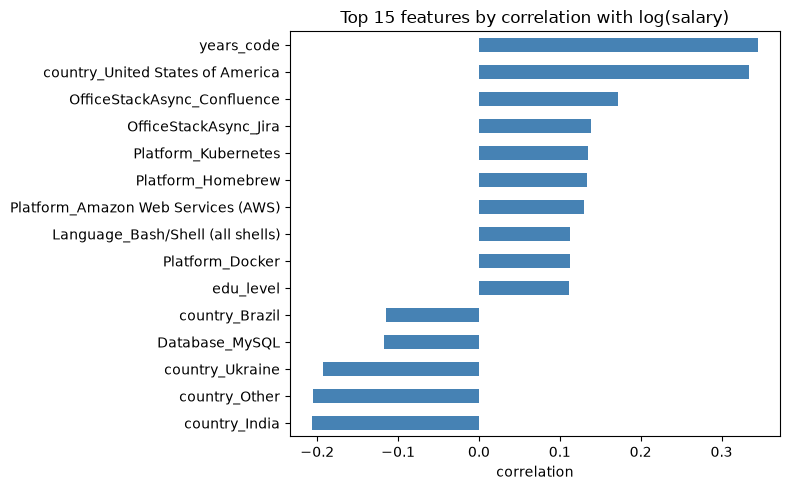

Dropped as near-duplicates: []
Features left: 86


In [9]:
# 1) Which features relate most to salary?
corr_target = X_train.corrwith(ytr_reg).dropna()
top15 = corr_target.reindex(corr_target.abs().sort_values(ascending=False).index).head(15)

top15.sort_values().plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.title("Top 15 features by correlation with log(salary)")
plt.xlabel("correlation")
plt.tight_layout()
plt.savefig("reports/correlation_with_salary.png", dpi=150)
plt.show()

# 2) Remove near-duplicate features (correlation above 0.9 with another feature)
corr_matrix = X_train.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > 0.9).any()]
print("Dropped as near-duplicates:", to_drop)
X_train_f = X_train.drop(columns=to_drop)
print("Features left:", X_train_f.shape[1])

Chi-square

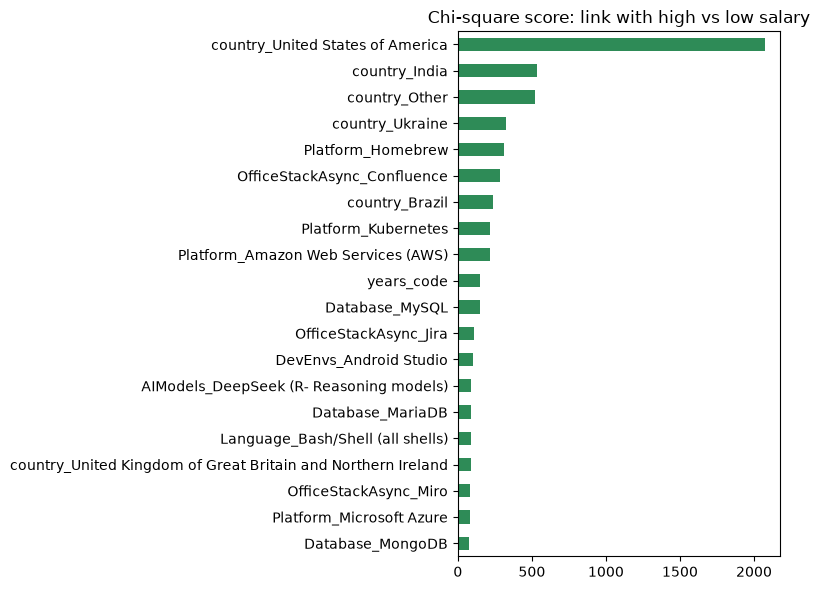

Selected features:
   years_code
   Language_Bash/Shell (all shells)
   Database_MySQL
   Database_MongoDB
   Database_MariaDB
   Platform_Amazon Web Services (AWS)
   Platform_Kubernetes
   Platform_Microsoft Azure
   Platform_Homebrew
   DevEnvs_Android Studio
   OfficeStackAsync_Jira
   OfficeStackAsync_Confluence
   OfficeStackAsync_Miro
   AIModels_DeepSeek (R- Reasoning models)
   country_Brazil
   country_India
   country_Other
   country_Ukraine
   country_United Kingdom of Great Britain and Northern Ireland
   country_United States of America


In [10]:
from sklearn.feature_selection import SelectKBest, chi2

# chi-square needs non-negative numbers -> use Min-Max scaling (0 to 1)
X_mm = MinMaxScaler().fit_transform(X_train_f)

k = min(20, X_train_f.shape[1])
selector = SelectKBest(chi2, k=k).fit(X_mm, ytr_cls)

scores = pd.Series(selector.scores_, index=X_train_f.columns).sort_values(ascending=False)
selected = list(X_train_f.columns[selector.get_support()])

scores.head(20).sort_values().plot(kind="barh", figsize=(8, 6), color="seagreen")
plt.title("Chi-square score: link with high vs low salary")
plt.tight_layout()
plt.savefig("reports/chi_square_scores.png", dpi=150)
plt.show()

print("Selected features:")
for f in selected:
    print("  ", f)

Save for the next steps

In [11]:
train = X_train.copy(); train["log_salary"] = ytr_reg; train["high_salary"] = ytr_cls
test = X_test.copy();  test["log_salary"] = yte_reg;  test["high_salary"] = yte_cls
train.to_csv("data/processed/train.csv", index=False)   # local only (gitignored)
test.to_csv("data/processed/test.csv", index=False)

with open("reports/selected_features.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(selected))
print("Saved train, test and selected_features.txt")

Saved train, test and selected_features.txt
